## Taller 4: Regresión Lineal

### Nombres de los Estudiantes:

**Diego Fernando Anacona Perez**

**Juan David Mora Rayo**

**Juan Sebastian Lizcano Quevedo**

**Repositorio:** [github.com/GORENTFUC/fuel-consumption-prediction](https://github.com/GORENTFUC/fuel-consumption-prediction.git)

#### Acerca del conjunto de datos

El conjunto de datos **Ship Fuel Efficiency** (archivo `ship_fuel_efficiency.csv`, disponible en Kaggle) contiene los registros mensuales de consumo de combustible y emisiones de CO2 de 120 embarcaciones que operan en rutas marítimas de Nigeria. Cada barco tiene un registro por cada mes del año, para un total de 1440 registros y 10 columnas, con variables continuas (distancia, consumo de combustible, emisiones y eficiencia del motor) y categóricas (tipo de barco, ruta, mes, tipo de combustible y condiciones del clima).

La pregunta que se quiere responder es: **¿qué variables explican el consumo de combustible de un barco y cuánto aporta cada una?** Conocer esto le sirve a una naviera para planear el combustible de cada viaje y controlar sus costos. Para el modelo se usa una variable dependiente (`fuel_consumption`) y dos variables independientes, que se escogen en la selección de variables.

#### Diccionario de Datos

| Variable           | Tipo        | Descripción |
|--------------------|-------------|-------------|
| ship_id            | Categórica  | Identificador del barco. |
| ship_type          | Categórica  | Tipo de barco: *Oil Service Boat*, *Fishing Trawler*, *Surfer Boat* y *Tanker Ship*. **Variable independiente del modelo.** |
| route_id           | Categórica  | Ruta recorrida: *Warri-Bonny*, *Port Harcourt-Lagos*, *Lagos-Apapa* y *Escravos-Lagos*. |
| month              | Categórica  | Mes del registro (enero a diciembre). |
| distance           | Decimal     | Distancia recorrida en el mes (millas náuticas). **Variable independiente del modelo.** |
| fuel_type          | Categórica  | Tipo de combustible: *Diesel* o *HFO* (fuelóleo pesado). |
| fuel_consumption   | Decimal     | Combustible consumido en el mes (litros). **Variable dependiente del modelo.** |
| CO2_emissions      | Decimal     | Emisiones de CO2 generadas en el mes (kilogramos). |
| weather_conditions | Categórica  | Condiciones del clima: *Calm* (calmado), *Moderate* (moderado) y *Stormy* (tormentoso). |
| engine_efficiency  | Decimal     | Eficiencia del motor (%). |

### Paso 1: Cargamos las librerías

In [1]:
# Libreria para procesos matemáticos
import numpy as np
# Libreria para manejo de datos
import pandas as pd
# Librerias para gráficas
import matplotlib.pyplot as plt
import seaborn as sns
# Libreria para la regresión lineal múltiple y la tabla ANOVA de las variables
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Librerias para verificar los supuestos del modelo
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Paso 2: Cargamos el conjunto de datos en un DataFrame

In [2]:
# Se cargan los datos a un DataFrame
datos = pd.read_csv('ship_fuel_efficiency.csv')
print('Registros y columnas:', datos.shape)
print('Datos faltantes:', datos.isna().sum().sum())
datos.head()

Registros y columnas: (1440, 10)
Datos faltantes: 0


,ship_id,ship_type,route_id,month,distance,fuel_type,fuel_consumption,CO2_emissions,weather_conditions,engine_efficiency
0,NG001,Oil Service Boat,Warri-Bonny,January,132.26,HFO,3779.77,10625.76,Stormy,92.14
1,NG001,Oil Service Boat,Port Harcourt-Lagos,February,128.52,HFO,4461.44,12779.73,Moderate,92.98
2,NG001,Oil Service Boat,Port Harcourt-Lagos,March,67.30,HFO,1867.73,5353.01,Calm,87.61
3,NG001,Oil Service Boat,Port Harcourt-Lagos,April,71.68,Diesel,2393.51,6506.52,Stormy,87.42
4,NG001,Oil Service Boat,Lagos-Apapa,May,134.32,HFO,4267.19,11617.03,Calm,85.61


### Paso 3: Exploración de variables

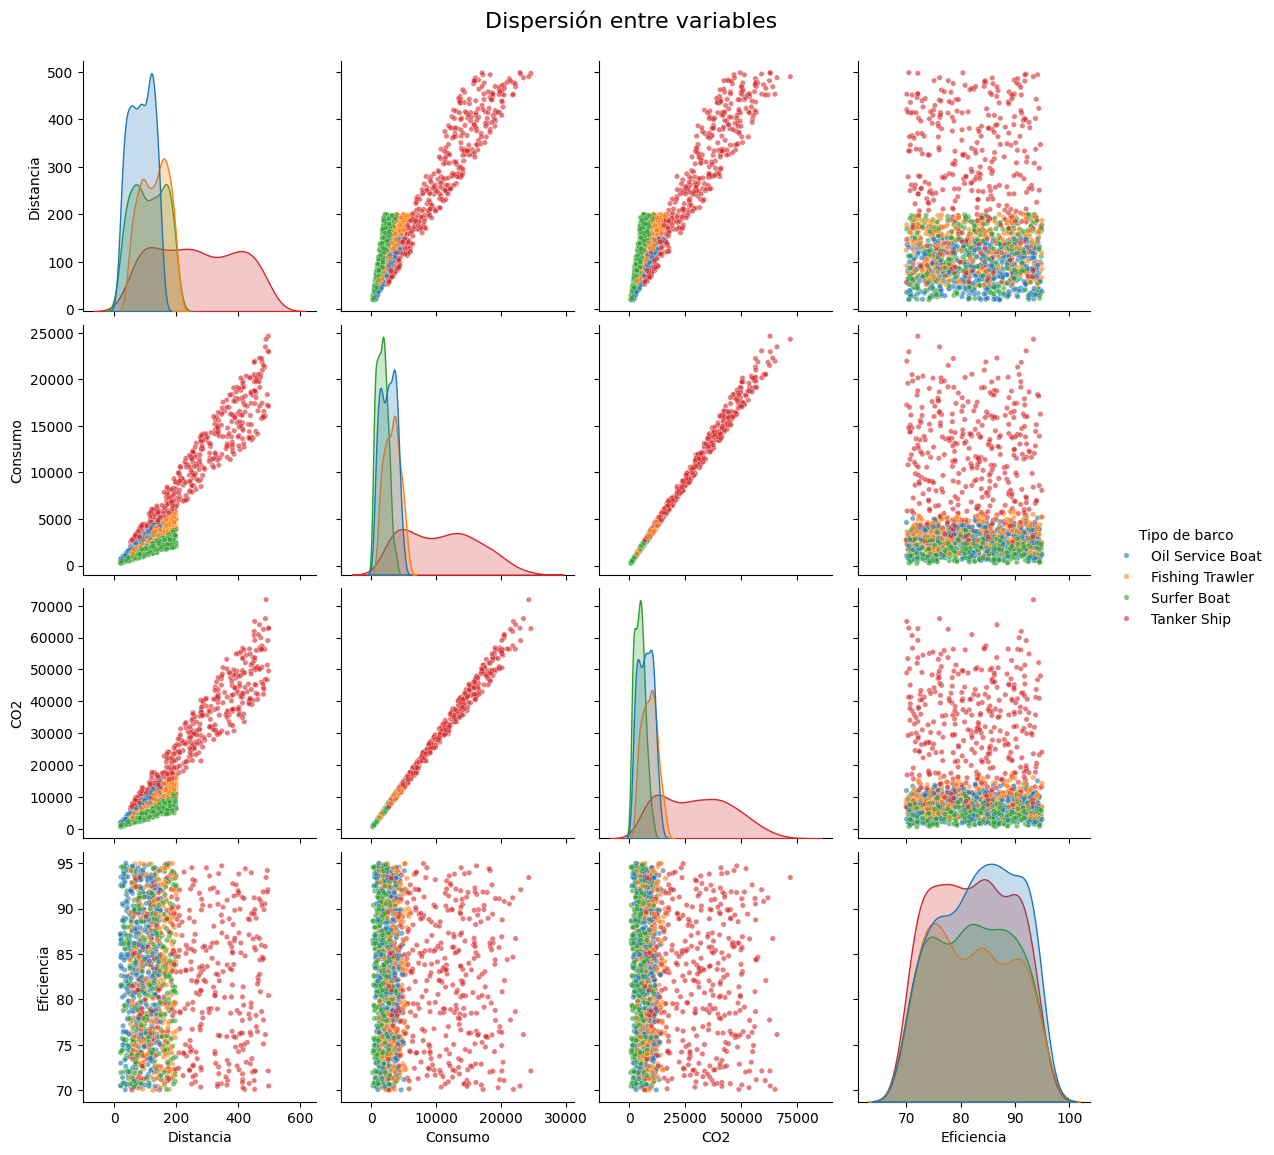

In [3]:
# Diagramas de dispersión entre todas las combinaciones de variables numéricas,
# coloreando los puntos por tipo de barco para ver también el efecto de esta variable categórica
variables_numericas = ['distance', 'fuel_consumption', 'CO2_emissions', 'engine_efficiency']

# Nombres cortos para que los ejes de la gráfica sean más fáciles de leer
nombres_cortos = {'distance': 'Distancia', 'fuel_consumption': 'Consumo',
                  'CO2_emissions': 'CO2', 'engine_efficiency': 'Eficiencia',
                  'ship_type': 'Tipo de barco'}

grafica = sns.pairplot(datos.rename(columns=nombres_cortos), vars=list(nombres_cortos.values())[:4],
                       hue='Tipo de barco', height=2.8, plot_kws={'s': 15, 'alpha': 0.6})
grafica.fig.suptitle('Dispersión entre variables', fontsize=16, y=1.03)
plt.show()

In [4]:
# Matriz de correlación entre las variables numéricas
datos[variables_numericas].corr().round(3)

,distance,fuel_consumption,CO2_emissions,engine_efficiency
distance,1.000,0.945,0.943,-0.026
fuel_consumption,0.945,1.000,0.997,-0.031
CO2_emissions,0.943,0.997,1.000,-0.030
engine_efficiency,-0.026,-0.031,-0.030,1.000


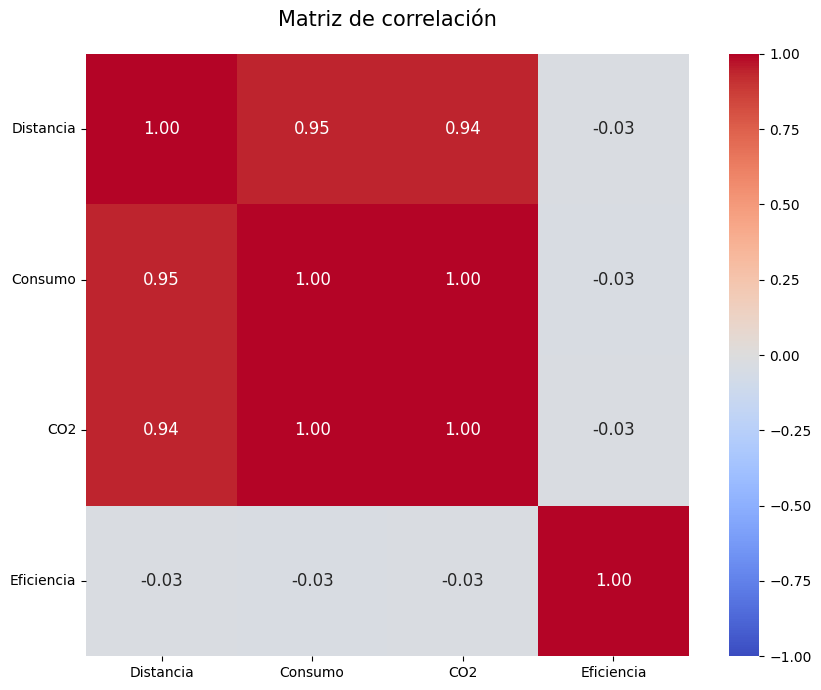

In [5]:
# Mapa de calor de la matriz de correlación (con 2 decimales)
plt.figure(figsize=(9, 7))
sns.heatmap(datos[variables_numericas].rename(columns=nombres_cortos).corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, square=True, annot_kws={'size': 12})
plt.title('Matriz de correlación', fontsize=15, pad=20)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
# Consumo promedio de combustible según cada variable categórica
for variable in ['ship_type', 'fuel_type', 'weather_conditions', 'route_id']:
    print(datos.groupby(variable)['fuel_consumption'].mean().round(1), '\n')

ship_type
Fishing Trawler      3229.2
Oil Service Boat     2619.4
Surfer Boat          1666.1
Tanker Ship         10780.4
Name: fuel_consumption, dtype: float64 

fuel_type
Diesel    4315.2
HFO       5723.4
Name: fuel_consumption, dtype: float64 

weather_conditions
Calm        5043.1
Moderate    4793.0
Stormy      4673.4
Name: fuel_consumption, dtype: float64 

route_id
Escravos-Lagos         4932.5
Lagos-Apapa            5171.5
Port Harcourt-Lagos    4805.1
Warri-Bonny            4353.3
Name: fuel_consumption, dtype: float64 



### Análisis

<div style="color: #D97706;">

- **Distancia y consumo:** Es la relación más clara de todas: en el diagrama de dispersión los puntos forman casi una línea recta hacia arriba y en la matriz de correlación tienen un 0.945 (color rojo intenso en el mapa de calor). O sea, entre más millas recorre un barco, más combustible gasta, y la relación sí parece lineal.

- **Emisiones de CO2:** El CO2 tiene una correlación de 0.997 con el consumo, prácticamente una línea perfecta. Esto pasa porque las emisiones se calculan a partir del combustible quemado (cada litro genera entre 2.5 y 3.0 kg de CO2), así que el CO2 es una consecuencia del consumo y no algo que lo explique.

- **Eficiencia del motor:** En los diagramas de dispersión la eficiencia del motor sale como una nube sin forma frente a todas las demás variables, y en el mapa de calor sus casillas salen en gris, con correlaciones de -0.03 frente a todas las variables. A simple vista no parece aportar nada.

- **Tipo de barco:** Los colores se separan bastante: los Tanker Ship (tanqueros) son los que más recorren y más gastan (10780 litros en promedio), mientras que los Surfer Boat son los que menos (1666 litros). Además, para una misma distancia cada tipo de barco forma su propia línea, lo que indica que el tipo de barco sí cambia el consumo.

- **Las demás categóricas:** El clima y la ruta muestran diferencias pequeñas en el consumo promedio. El combustible HFO sale con un consumo mayor que el diésel, pero hay que tener cuidado, porque los Surfer Boat (los que menos gastan) solo usan diésel y eso le baja el promedio al diésel.

</div>

### Paso 4: Selección de variables

Para escoger las variables del modelo se siguió este proceso:

1. **Relevancia:** Se descartan antes de modelar `ship_id`, porque es solo un identificador, y `CO2_emissions`, porque se calcula a partir del mismo consumo de combustible (usarla para predecir el consumo sería hacer trampa).
2. **Significancia estadística:** Se ajusta un modelo con todas las variables candidatas y se revisa la tabla ANOVA (tipo II), que da un solo valor p por variable (incluso para las categóricas con varias categorías). Se descartan las variables con valor p mayor a 0.05.
3. **Interpretabilidad:** De las variables significativas se dejan solo las dos que más aportan (mayor estadístico F), para tener un modelo con una variable dependiente y dos independientes que sea fácil de interpretar. Se compara el R² ajustado para confirmar que la variable que se deja por fuera no hace falta.

In [7]:
# Modelo completo con todas las variables candidatas; C() indica que la variable es categórica
modelo_completo = smf.ols('fuel_consumption ~ distance + engine_efficiency + C(ship_type) + C(fuel_type)'
                          ' + C(weather_conditions) + C(route_id) + C(month)', data=datos).fit()

# Tabla ANOVA tipo II: un valor p por cada variable
sm.stats.anova_lm(modelo_completo, typ=2).round(4)

,sum_sq,df,F,PR(>F)
C(ship_type),1.631667e+09,3.0,398.1625,0.0000
C(fuel_type),1.422157e+07,1.0,10.4111,0.0013
C(weather_conditions),4.729730e+06,2.0,1.7312,0.1774
C(route_id),4.018426e+06,3.0,0.9806,0.4010
C(month),8.927108e+06,11.0,0.5941,0.8350
distance,1.170698e+10,1.0,8570.2801,0.0000
engine_efficiency,2.346199e+06,1.0,1.7176,0.1902
Residual,1.935618e+09,1417.0,NaN,NaN


In [8]:
# Modelo final: consumo de combustible (dependiente) explicado por distancia y tipo de barco (independientes)
modelo = smf.ols('fuel_consumption ~ distance + C(ship_type)', data=datos).fit()
print(modelo.summary())

# Comparación del R² ajustado al ir agregando variables
print()
for formula in ['fuel_consumption ~ distance',
                'fuel_consumption ~ distance + C(ship_type)',
                'fuel_consumption ~ distance + C(ship_type) + C(fuel_type)']:
    print(f'{formula:60} R² ajustado: {smf.ols(formula, data=datos).fit().rsquared_adj:.4f}')

                            OLS Regression Results                            
Dep. Variable:       fuel_consumption   R-squared:                       0.943
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     5912.
Date:                Mon, 05 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:02:32   Log-Likelihood:                -12216.
No. Observations:                1440   AIC:                         2.444e+04
Df Residuals:                    1435   BIC:                         2.447e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercep

### Análisis

<div style="color: #D97706;">

- **Variables descartadas:** En la tabla ANOVA, la eficiencia del motor ($p = 0.190$), el clima ($p = 0.177$), la ruta ($p = 0.401$) y el mes ($p = 0.835$) tienen valores p mayores a 0.05, así que no aportan de forma significativa a explicar el consumo. Esto confirma lo que ya se veía en los diagramas de dispersión y en la matriz de correlación.

- **Variables seleccionadas:** Las dos variables con más peso son la distancia ($F = 8570$) y el tipo de barco ($F = 398$), ambas con $p < 0.001$. El tipo de combustible también salió significativo ($p = 0.001$), pero con un $F$ de apenas 10.4, y al agregarlo al modelo el R² ajustado solo sube de 0.9426 a 0.9430. Por eso se deja por fuera: complica el modelo sin mejorar casi nada.

- **Ajuste del modelo:** Solo con la distancia el modelo explica el 89.3 % del consumo, y al agregar el tipo de barco sube al 94.3 %. O sea, con estas dos variables ya se explica casi todo el consumo de combustible.

- **Coeficientes:** Por cada milla náutica adicional el consumo sube en promedio 36.3 litros. Frente a un Fishing Trawler (la categoría de referencia), un Tanker Ship gasta 2494 litros más, un Oil Service Boat 882 litros más y un Surfer Boat 969 litros menos, recorriendo la misma distancia.

</div>

### Paso 5: Verificación de supuestos del modelo

Se revisan los cinco supuestos de la regresión lineal múltiple:

- **Linealidad:** gráfico de residuos contra valores ajustados (los puntos deben quedar alrededor de 0, sin formar curvas).
- **Normalidad de los residuos:** gráfico Q-Q y prueba de Shapiro-Wilk (H0: los residuos son normales).
- **Homocedasticidad (varianza constante):** prueba de Breusch-Pagan (H0: la varianza de los residuos es constante).
- **Independencia de los residuos:** estadístico de Durbin-Watson (debe estar cerca de 2).
- **No multicolinealidad:** factor de inflación de la varianza VIF (debe ser menor a 5).

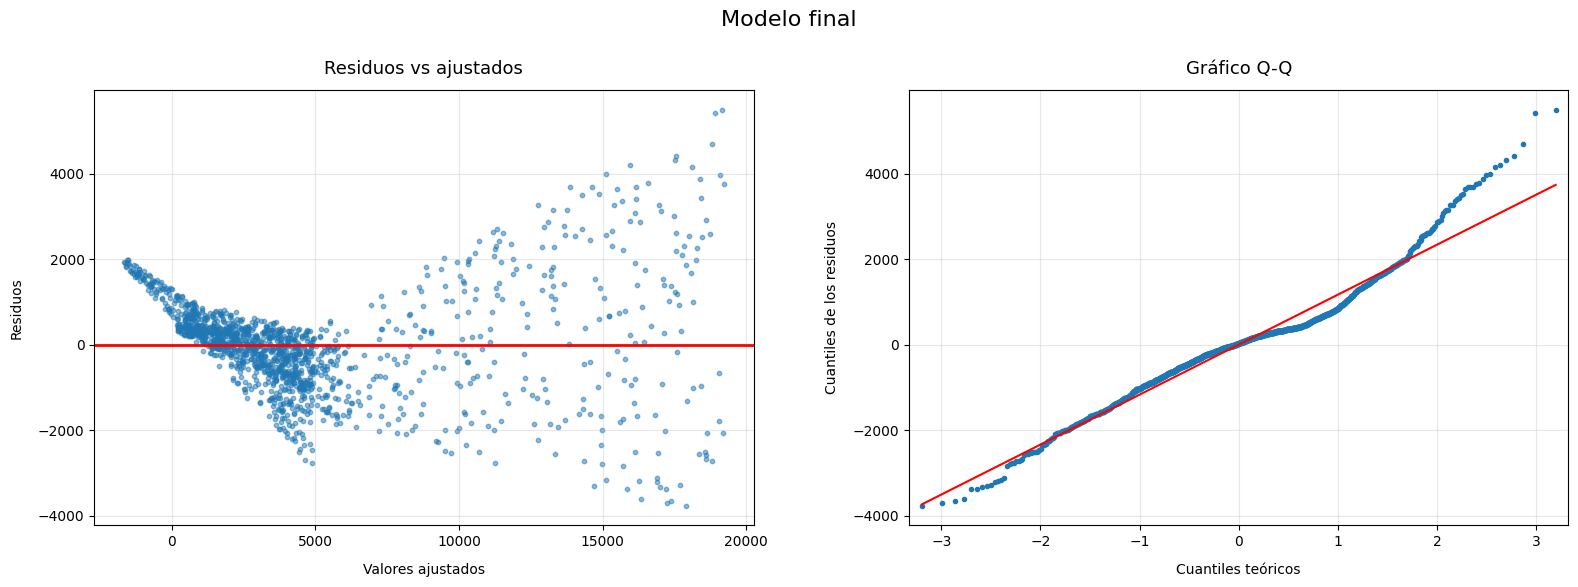

Shapiro-Wilk (normalidad):      p-value = 2.532588986512427e-18
Breusch-Pagan (homocedasticidad): p-value = 7.941656585914942e-121
Durbin-Watson (independencia):   1.968


In [9]:
def verificar_supuestos(modelo_ajustado, titulo):
    """Grafica los residuos y calcula las pruebas de normalidad, homocedasticidad e independencia."""
    residuos = modelo_ajustado.resid

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(titulo, fontsize=16)
    # Linealidad y homocedasticidad: residuos contra valores ajustados
    axes[0].scatter(modelo_ajustado.fittedvalues, residuos, s=10, alpha=0.5)
    axes[0].axhline(y=0, color='red', linewidth=2)
    axes[0].set_title('Residuos vs ajustados', fontsize=13, pad=12)
    axes[0].set_xlabel('Valores ajustados', labelpad=10)
    axes[0].set_ylabel('Residuos', labelpad=10)
    axes[0].grid(alpha=0.3)
    # Normalidad: gráfico Q-Q de los residuos
    sm.qqplot(residuos, line='s', ax=axes[1], markersize=3)
    axes[1].set_title('Gráfico Q-Q', fontsize=13, pad=12)
    axes[1].set_xlabel('Cuantiles teóricos', labelpad=10)
    axes[1].set_ylabel('Cuantiles de los residuos', labelpad=10)
    axes[1].grid(alpha=0.3)
    plt.tight_layout(pad=1.5, w_pad=4)
    plt.show()

    print('Shapiro-Wilk (normalidad):      p-value =', stats.shapiro(residuos).pvalue)
    print('Breusch-Pagan (homocedasticidad): p-value =', het_breuschpagan(residuos, modelo_ajustado.model.exog)[1])
    print('Durbin-Watson (independencia):  ', round(durbin_watson(residuos), 3))


verificar_supuestos(modelo, 'Modelo final')

In [10]:
# Multicolinealidad: VIF de cada variable explicativa (se excluye la constante)
X = modelo.model.exog
pd.DataFrame({'variable': modelo.model.exog_names[1:],
              'VIF': [round(variance_inflation_factor(X, i), 2) for i in range(1, X.shape[1])]})

,variable,VIF
0,C(ship_type)[T.Oil Service Boat],1.75
1,C(ship_type)[T.Surfer Boat],1.62
2,C(ship_type)[T.Tanker Ship],2.31
3,distance,1.86


### Análisis

<div style="color: #D97706;">

- **Linealidad:** No se cumple del todo. En el gráfico de residuos contra valores ajustados, en la parte izquierda (consumos bajos) los puntos forman una franja diagonal en lugar de una nube alrededor de 0. Esto pasa porque cada tipo de barco gasta una cantidad distinta de combustible por milla, y el modelo supone que todos suben al mismo ritmo (36.3 litros por milla) y solo los mueve hacia arriba o hacia abajo.

- **Homocedasticidad:** Este supuesto no se cumple. En el mismo gráfico los puntos se van abriendo como un embudo: para consumos bajos los residuos son pequeños y para consumos altos son mucho más grandes. La prueba de Breusch-Pagan lo confirma con un $p$-value prácticamente de 0, así que se rechaza que la varianza sea constante. Tiene lógica: no es lo mismo equivocarse en un barco que gasta 300 litros que en uno que gasta 20000.

- **Normalidad:** Tampoco se cumple del todo. En el gráfico Q-Q los extremos se salen de la línea y la prueba de Shapiro-Wilk da un $p$-value prácticamente de 0, por lo que se rechaza que los residuos sean normales.

- **Independencia:** El Durbin-Watson dio 1.968, muy cerca de 2, así que los residuos son independientes entre sí.

- **Multicolinealidad:** Todos los VIF están por debajo de 2.4, muy lejos del límite de 5, así que la distancia y el tipo de barco no están repitiendo la misma información.

- **Qué hacer:** Como fallan la linealidad, la homocedasticidad y la normalidad, el modelo explica bien el consumo, pero sus valores p e intervalos de confianza no son del todo confiables. Una alternativa común cuando la variación crece con el tamaño de los datos es aplicar logaritmo a la variable de respuesta y a la distancia, que es lo que se prueba a continuación.

</div>

#### Alternativa: modelo con transformación logarítmica

R² ajustado modelo logarítmico: 0.9743



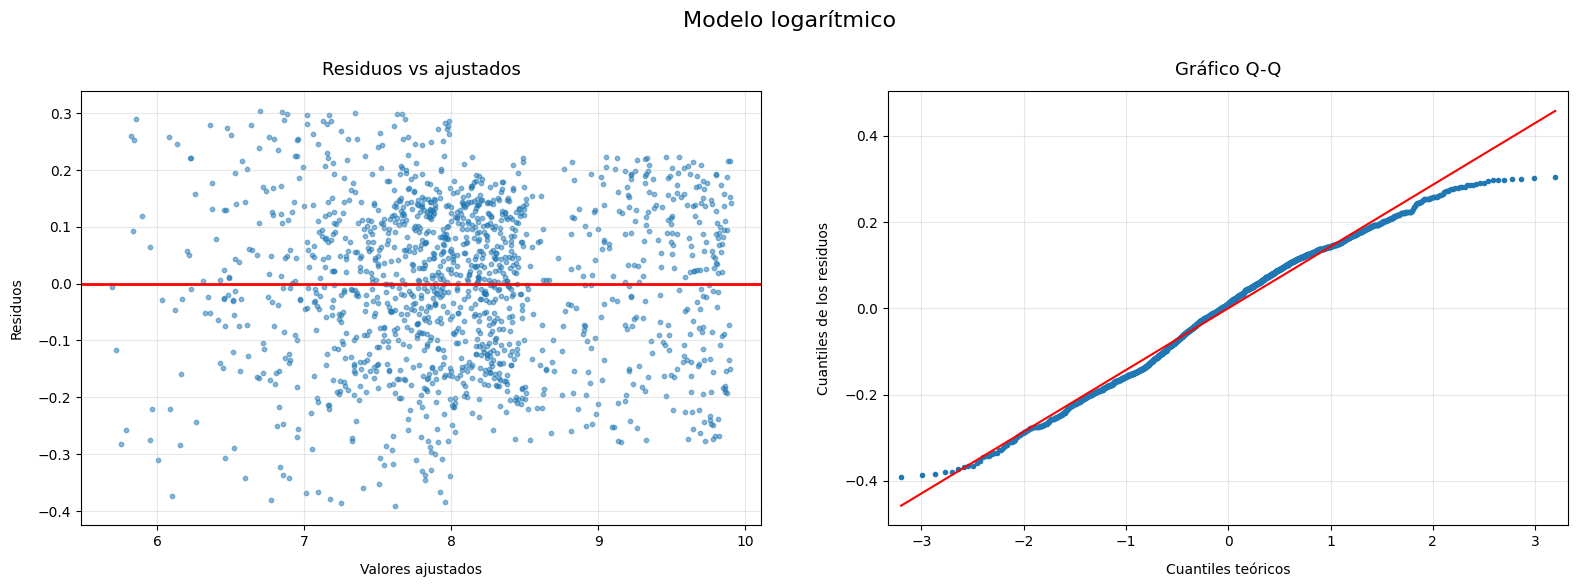

Shapiro-Wilk (normalidad):      p-value = 9.696954917575093e-11
Breusch-Pagan (homocedasticidad): p-value = 1.2140759737312577e-62
Durbin-Watson (independencia):   2.064


In [11]:
# Se aplica logaritmo al consumo y a la distancia para reducir el efecto embudo de los residuos
modelo_log = smf.ols('np.log(fuel_consumption) ~ np.log(distance) + C(ship_type)', data=datos).fit()
print('R² ajustado modelo logarítmico:', round(modelo_log.rsquared_adj, 4))
print()

verificar_supuestos(modelo_log, 'Modelo logarítmico')

In [12]:
# Como la varianza sigue sin ser constante, se calculan errores estándar robustos (HC3),
# que corrigen los valores p sin necesidad de que se cumpla la homocedasticidad
modelo_log_robusto = modelo_log.get_robustcov_results(cov_type='HC3')
print(modelo_log_robusto.summary())

                               OLS Regression Results                               
Dep. Variable:     np.log(fuel_consumption)   R-squared:                       0.974
Model:                                  OLS   Adj. R-squared:                  0.974
Method:                       Least Squares   F-statistic:                 1.226e+04
Date:                      Mon, 05 Oct 2026   Prob (F-statistic):               0.00
Time:                              22:02:33   Log-Likelihood:                 755.87
No. Observations:                      1440   AIC:                            -1502.
Df Residuals:                          1435   BIC:                            -1475.
Df Model:                                 4                                         
Covariance Type:                        HC3                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------

### Análisis

<div style="color: #D97706;">

- **Mejora del ajuste:** El modelo con logaritmos sube el R² ajustado de 0.943 a 0.974, o sea que ahora explica el 97.4 % de la variación del consumo.

- **Residuos:** Con los logaritmos desaparecen la franja diagonal y el embudo: los residuos quedan como una nube pareja alrededor de 0, así que ahora sí se cumple la linealidad. En el gráfico Q-Q los puntos también quedan mucho más pegados a la línea. Aun así, las pruebas de Shapiro-Wilk y Breusch-Pagan siguen dando $p$-value menores a 0.05, porque con 1440 datos estas pruebas detectan hasta desviaciones pequeñas. La diferencia que queda viene de que cada tipo de barco tiene una variación distinta (por ejemplo, los Surfer Boat varían más que los demás).

- **Errores robustos:** Para que los valores p sean confiables a pesar de esto, se usaron errores estándar robustos (HC3). Con ellos todas las variables siguen siendo significativas: la distancia y los tres tipos de barco tienen $p$-value menores a 0.05. El Durbin-Watson (2.064) sigue mostrando residuos independientes.

</div>

### Conclusión

<div style="color: #D97706;">

- **Modelo final:** El modelo que mejor responde la pregunta es la regresión lineal múltiple, que explica el 97.4 % del consumo de combustible con solo dos variables independientes: la distancia recorrida y el tipo de barco. El clima, la ruta, el mes y la eficiencia del motor no resultaron significativos, y el tipo de combustible casi no mejoraba el modelo, así que no hacen falta para explicar el consumo en estos datos.

- **Distancia:** Su coeficiente dio 1.00, lo que quiere decir que el consumo es proporcional a la distancia: si un barco navega un 10 % más, gasta un 10 % más de combustible.

- **Tipo de barco:** Es lo que más diferencia el consumo después de la distancia. Recorriendo las mismas millas, y comparando con un Fishing Trawler, un Tanker Ship gasta cerca de un 59 % más ($e^{0.465} = 1.59$), un Oil Service Boat un 20 % más y un Surfer Boat un 41 % menos.

- **Para la naviera:** Para planear el combustible de un viaje basta con conocer la distancia y el tipo de barco; no vale la pena ajustar el plan por el clima, la ruta o el mes. Y si se quiere bajar el consumo (y con él las emisiones de CO2, que dependen directamente del combustible), lo que más pesa es reducir las millas navegadas y escoger bien qué tipo de barco se usa para cada trabajo.

</div>